## Recommending exercises (Goal 3, part 2)

**Goal 3:** a model that recommends tabletop exercises based on **threat type, difficulty and required skills**, with an evaluation.

**Input:** what a trainer wants to practise, e.g. *Ransomware*, *Basic*, *Communication*.
**Output:** the 16 exercises ranked by how well they fit, with their response options from Goal 2.

**Model type: content-based recommender.** Each exercise gets a *profile* that describes its content: which threats its events contain and which skills and difficulty levels its questions need. A request is compared with every profile and the best-fitting exercises are returned. This type of recommender is used when there is no history of what users chose before (which would be needed for collaborative filtering), as is the case here.

Requires `5_goal1_scenario_analysis` (reviewed labels), `6_CisaMitreCombining` (for `goal2_exercise_model.csv`) and `7_label_questions` (for `cisa_questions_labeled.csv`) to have been run first.

**Note on "machine learning":** this recommender has no trained parameters; it is a content-based scoring model. Whether that fulfils the "machine learning model" wording of Goal 3 is being checked with the supervisor.

#### 1. Loading the data
*Why:* the recommender combines three earlier results: the exercises (`4`), the reviewed threat labels of the events (`3`, reviewed in `5`) and the skill/difficulty labels of the questions (`7`). The Goal 2 table (`6`) is used to show response options next to each recommendation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("../data/processed")
if not data_dir.exists():
    data_dir = Path("data/processed")

for needed, notebook in [("cisa_events_reviewed.csv", "5_goal1_scenario_analysis"),
                         ("goal2_exercise_model.csv", "6_CisaMitreCombining"),
                         ("cisa_questions_labeled.csv", "7_label_questions")]:
    assert (data_dir / needed).exists(), f"{needed} is missing. Run {notebook} first."

questions = pd.read_csv(data_dir / "cisa_questions_labeled.csv")
exercises = pd.read_csv(data_dir / "cisa_exercises.csv")
goal2 = pd.read_csv(data_dir / "goal2_exercise_model.csv")

# use the reviewed labels from the Goal 1 notebook, so all three goals use the same labels
events = pd.read_csv(data_dir / "cisa_classified_events.csv").merge(
    pd.read_csv(data_dir / "cisa_events_reviewed.csv"), on="inject_id", validate="one_to_one")
events["threat_category"] = events["reviewed_threat"]
events["impact_category"] = events["reviewed_impact"]

print("Exercises:", len(exercises), "| events:", len(events), "| labelled questions:", len(questions))
pd.set_option("display.max_colwidth", 100)

Exercises: 16 | events: 66 | labelled questions: 425


#### 2. Linking questions and events to exercises
`cisa_exercises.csv` lists the question and event IDs of each exercise as `"; "`-separated text, which is split into one row per link.

*Why:* the profiles in step 3 are built by counting labels per exercise. The 20 Executives general questions belong to both Executives vignettes, so they are counted in both. The five question fragments that `7` merged into `EX-Q-134` no longer exist and simply drop out of the join; the check makes sure nothing else is lost.

In [2]:
def explode_ids(column, id_name):
    return (exercises[["exercise_id", column]]
            .assign(**{id_name: exercises[column].str.split("; ")})
            .explode(id_name)[["exercise_id", id_name]])

exercise_questions = explode_ids("question_ids", "question_id").merge(questions, on="question_id")
exercise_events = explode_ids("event_ids", "inject_id").merge(events, on="inject_id")

merged_fragments = {f"EX-Q-{i}" for i in range(135, 140)}
lost = set(explode_ids("question_ids", "question_id")["question_id"]) - set(questions["question_id"]) - merged_fragments
assert not lost, f"Questions missing from the labelled file: {lost}"
assert exercise_events["inject_id"].nunique() == len(events), "Some events are not in any exercise"

print("Question links:", len(exercise_questions), "| event links:", len(exercise_events))

Question links: 445 | event links: 66


#### 3. Exercise profiles
Each exercise is described by three sets of shares:
- **threats:** share of its *incident* events per threat category (alerts and "nothing happened" events are left out, because they do not train a threat)
- **skills:** share of its questions per required skill
- **difficulty:** share of its questions per difficulty level

*Why shares and not counts:* exercises have different numbers of events and questions (1 to 7 events, 21 to 37 questions). Shares make them comparable, so a long exercise does not win just because it is long.

In [3]:
ids = exercises["exercise_id"].tolist()
incidents = exercise_events[exercise_events["threat_category"] != "No Confirmed Incident"]

threat_share = pd.crosstab(incidents["exercise_id"], incidents["threat_category"], normalize="index").reindex(ids, fill_value=0)
skill_counts = pd.crosstab(exercise_questions["exercise_id"], exercise_questions["required_skill"]).reindex(ids, fill_value=0)
level_counts = pd.crosstab(exercise_questions["exercise_id"], exercise_questions["difficulty_level"]).reindex(ids, fill_value=0)

THREATS = threat_share.columns.tolist()
SKILLS = skill_counts.columns.tolist()
LEVELS = ["Basic", "Intermediate", "Advanced"]

# a readable summary of each profile
level_score = (level_counts[LEVELS] * [1, 2, 3]).sum(axis=1) / level_counts.sum(axis=1)
profiles = pd.DataFrame({
    "manual_title": exercises.set_index("exercise_id")["manual_title"],
    "section": exercises.set_index("exercise_id")["section"],
    "main_threats": threat_share.apply(lambda r: "; ".join(r[r > 0].sort_values(ascending=False).index), axis=1),
    "top_skills": skill_counts.apply(lambda r: "; ".join(r.sort_values(ascending=False).index[:3]), axis=1),
    "avg_difficulty": level_score.round(2),
}).loc[ids]

print("Threat categories:", THREATS)
print("Skills:", SKILLS)
profiles

Threat categories: ['Data Exposure', 'Denial of Service', 'Insider Threat / Unauthorized Access', 'Other Security Incident', 'Phishing', 'Ransomware', 'System Disruption', 'Third-Party / Supply Chain', 'Vulnerability']
Skills: ['Business Continuity & Recovery', 'Communication', 'Incident Response', 'Leadership & Decision-Making', 'Legal & Compliance', 'Risk Management', 'Technical Controls', 'Third-Party Management', 'Threat Detection & Monitoring', 'Training & Awareness']


,manual_title,section,main_threats,top_skills,avg_difficulty
exercise_id,,,,,
EX-01,Healthcare,Module 1,Phishing; System Disruption; Vulnerability,Technical Controls; Risk Management; Training & Awareness,1.79
EX-02,Healthcare,Module 2,Data Exposure; Insider Threat / Unauthorized Access; Other Security Incident; Ransomware; System...,Business Continuity & Recovery; Incident Response; Communication,1.96
EX-03,Vendor,Module 1,Third-Party / Supply Chain,Technical Controls; Third-Party Management; Risk Management,1.71
EX-04,Vendor,Module 2 – 6 months later,System Disruption; Other Security Incident; Third-Party / Supply Chain,Incident Response; Business Continuity & Recovery; Third-Party Management,1.90
EX-05,Ransomware,Module 1,Other Security Incident; Phishing; Vulnerability,Risk Management; Training & Awareness; Business Continuity & Recovery,1.67
EX-06,Ransomware,Module 2,Data Exposure; Ransomware,Incident Response; Business Continuity & Recovery; Communication,2.12
EX-07,Insider Threat,Module 1,Vulnerability; Data Exposure,Training & Awareness; Risk Management; Threat Detection & Monitoring,1.64
EX-08,Insider Threat,Module 2,Insider Threat / Unauthorized Access; Third-Party / Supply Chain; Vulnerability,Business Continuity & Recovery; Incident Response; Technical Controls,1.84
EX-09,Executives,Vignette 1: Whaling/Ransomware,Ransomware,Leadership & Decision-Making; Legal & Compliance; Communication,1.94


#### 4. The recommender
For a request (threat, difficulty, skill), each exercise gets a **match score**:

> score = share of the exercise's incidents with that threat + share of its questions needing that skill + share of its questions at that difficulty

Each part is between 0 and 1, so the score is between 0 and 3. Any of the three criteria can be left out (`None`). The three parts get equal weight on purpose: there is no data to learn better weights from, and equal weights keep the evaluation in step 6 fair, because nothing is tuned on the test questions.

*Why this design:* the score can be explained to a trainer ("60% of this exercise's questions are about communication"), which matters more for a training tool than a slightly more complex model.

In [4]:
def match_scores(threat=None, skill=None, difficulty=None, skills=skill_counts, levels=level_counts):
    score = pd.Series(0.0, index=ids)
    if threat is not None:
        score += threat_share[threat] if threat in threat_share else 0
    if skill is not None:
        score += skills[skill] / skills.sum(axis=1)
    if difficulty is not None:
        score += levels[difficulty] / levels.sum(axis=1)
    return score

def recommend(threat=None, skill=None, difficulty=None, top_n=3):
    for value, allowed in [(threat, THREATS), (skill, SKILLS), (difficulty, LEVELS)]:
        assert value is None or value in allowed, f"'{value}' is not one of {allowed}"
    result = profiles.copy()
    result["score"] = match_scores(threat, skill, difficulty).round(2)
    if threat is not None:
        result["threat_share"] = threat_share[threat].round(2)
    if skill is not None:
        result["skill_share"] = (skill_counts[skill] / skill_counts.sum(axis=1)).round(2)
    if difficulty is not None:
        result["difficulty_share"] = (level_counts[difficulty] / level_counts.sum(axis=1)).round(2)
    result = result.join(goal2.set_index("exercise_id")[["top_responses", "outcomes"]])
    first = ["manual_title", "section", "score"] + [c for c in ["threat_share", "skill_share", "difficulty_share"] if c in result]
    result = result[first + [c for c in result.columns if c not in first]]
    return result.sort_values("score", ascending=False).head(top_n)

#### 5. Example recommendations
*Why:* before measuring anything, it is worth checking that the output makes sense for realistic requests. The `*_share` columns show *why* each exercise was ranked where it is.

In [5]:
print("Ransomware, Basic, Communication")
display(recommend("Ransomware", "Communication", "Basic"))

print("Third-Party / Supply Chain, Intermediate, Third-Party Management")
display(recommend("Third-Party / Supply Chain", "Third-Party Management", "Intermediate"))

print("Any threat, Advanced, Leadership & Decision-Making")
display(recommend(skill="Leadership & Decision-Making", difficulty="Advanced"))

Ransomware, Basic, Communication


,manual_title,section,score,threat_share,skill_share,difficulty_share,main_threats,top_skills,avg_difficulty,top_responses,outcomes
exercise_id,,,,,,,,,,,
EX-14,Financial Services,Module 2,1.42,1.0,0.15,0.27,Ransomware,Incident Response; Business Continuity & Recovery; Communication,1.85,Behavior Prevention on Endpoint; Data Backup; Execution Prevention; Operating System Configurati...,Operational Disruption; Reputational Damage
EX-09,Executives,Vignette 1: Whaling/Ransomware,1.28,1.0,0.06,0.22,Ransomware,Leadership & Decision-Making; Legal & Compliance; Communication,1.94,Antivirus/Antimalware; Audit; Behavior Prevention on Endpoint; Data Backup; Network Intrusion Pr...,Operational Disruption
EX-12,Industrial Control Systems,Module 2,0.91,0.5,0.00,0.41,Ransomware; Data Exposure; System Disruption,Incident Response; Business Continuity & Recovery; Threat Detection & Monitoring,1.67,User Account Management; Communication Authenticity; Data Backup; Filter Network Traffic; Networ...,Operational Disruption; Data Exposure


Third-Party / Supply Chain, Intermediate, Third-Party Management


,manual_title,section,score,threat_share,skill_share,difficulty_share,main_threats,top_skills,avg_difficulty,top_responses,outcomes
exercise_id,,,,,,,,,,,
EX-03,Vendor,Module 1,1.89,1.00,0.25,0.64,Third-Party / Supply Chain,Technical Controls; Third-Party Management; Risk Management,1.71,Multi-factor Authentication; Network Segmentation; User Account Management; Update Software; Vul...,No Direct Impact; Security Risk
EX-04,Vendor,Module 2 – 6 months later,1.25,0.25,0.19,0.81,System Disruption; Other Security Incident; Third-Party / Supply Chain,Incident Response; Business Continuity & Recovery; Third-Party Management,1.90,Network Segmentation; User Account Management; Filter Network Traffic; Out-of-Band Communication...,Operational Disruption; Security Risk
EX-11,Industrial Control Systems,Module 1,1.15,0.33,0.12,0.69,Insider Threat / Unauthorized Access; Phishing; Third-Party / Supply Chain,Training & Awareness; Incident Response; Technical Controls,1.88,Audit; User Training; Account Use Policies; Active Directory Configuration; Application Develope...,No Direct Impact; Security Risk


Any threat, Advanced, Leadership & Decision-Making


,manual_title,section,score,skill_share,difficulty_share,main_threats,top_skills,avg_difficulty,top_responses,outcomes
exercise_id,,,,,,,,,,
EX-10,Executives,Vignette 2: Insider Threat,0.75,0.50,0.25,Insider Threat / Unauthorized Access,Leadership & Decision-Making; Communication; Incident Response,2.00,Account Use Policies; Active Directory Configuration; Application Developer Guidance; Disable or...,Data Exposure
EX-09,Executives,Vignette 1: Whaling/Ransomware,0.69,0.53,0.16,Ransomware,Leadership & Decision-Making; Legal & Compliance; Communication,1.94,Antivirus/Antimalware; Audit; Behavior Prevention on Endpoint; Data Backup; Network Intrusion Pr...,Operational Disruption
EX-02,Healthcare,Module 2,0.37,0.15,0.22,Data Exposure; Insider Threat / Unauthorized Access; Other Security Incident; Ransomware; System...,Business Continuity & Recovery; Incident Response; Communication,1.96,Encrypt Sensitive Information; Restrict File and Directory Permissions; User Account Management;...,Security Risk; Patient Safety; Operational Disruption; Data Exposure; Reputational Damage


#### 6. Evaluation setup
There are no real users yet, so the evaluation uses the questions themselves as test requests (**leave-one-out**):

1. Take one question, e.g. a *Basic Communication* question asked after a *Ransomware* event.
2. Turn it into a request: (*Ransomware*, *Communication*, *Basic*).
3. **Remove every copy of that question text from all exercise profiles.** The manuals reuse many questions (267 of the 445 exercise–question links have a text that appears more than once), so removing only one copy would leave identical questions in the profiles and make the test too easy.
4. Check where the recommender ranks the exercise(s) the question came from. If the same text appears in several exercises, all of them count as correct.

The threat of a question is the threat category of the event it follows (same manual, section and day). Questions after an alert, and the general Executives questions, have no threat, so their request uses only skill and difficulty.

**Metrics:**
- **Hit@3:** how often a correct exercise is in the top 3
- **MRR** (mean reciprocal rank): 1 if a correct exercise is first, 1/2 if second, 1/3 if third, and so on, averaged

**Ties** are counted pessimistically: if several exercises have the same score, the correct one is placed last among them. Otherwise a model that gives everything the same score could look good by luck.

*Why leave-one-out instead of a train/test split:* the model has no trained parameters (the weights are fixed in step 4), so there is nothing to overfit. Removing the test question from the profiles is what keeps the test honest.

**What this test does and does not show:** the requests come from the same rule-labelled questions that the profiles are built from. So it shows that the profiles tell the exercises apart, but not that real trainers would find the recommendations useful. An independent test with trainer requests judged by the team would be the next step.

In [6]:
question_threat = (events.assign(day=events["day"].fillna(""))
                   [["manual_title", "section", "day", "threat_category"]])
tests = (exercise_questions.assign(day=exercise_questions["day"].fillna(""))
         .merge(question_threat, on=["manual_title", "section", "day"], how="left"))
tests.loc[tests["threat_category"] == "No Confirmed Incident", "threat_category"] = np.nan
tests["threat_category"] = tests["threat_category"].astype(object).where(tests["threat_category"].notna(), None)

correct_exercises = exercise_questions.groupby("question_text")["exercise_id"].apply(set)

def rank_of_correct(score, correct):
    # pessimistic rank: everything scoring higher or equal is placed before the correct exercise
    return min(int((score >= score[c]).sum()) for c in correct)

print("Test requests:", len(tests))
print("  with a threat:", tests["threat_category"].notna().sum(), "| skill + difficulty only:", tests["threat_category"].isna().sum())

Test requests: 445
  with a threat: 324 | skill + difficulty only: 121


#### 7. Running the evaluation
The full recommender is compared with:
- **Random:** exercises in random order (average of 200 shuffles). This is what guessing gives.
- **Most questions first:** always the same order, longest exercises first. A naive "popular" baseline.
- **One criterion only:** the recommender using only the threat, only the skill, or only the difficulty. This shows how much each part contributes.

*Why baselines:* a number like "hit@3 = 80%" means little on its own. It only shows the model works if it clearly beats these simple alternatives.

In [7]:
# every (exercise, skill, level) occurrence of each question text, so all copies can be left out
copies = (exercise_questions
          .groupby(["question_text", "exercise_id", "required_skill", "difficulty_level"])
          .size().rename("n").reset_index())
copies_by_text = {text: group for text, group in copies.groupby("question_text")}

def evaluate(use_threat=True, use_skill=True, use_difficulty=True):
    ranks = []
    for t in tests.itertuples():
        skills = skill_counts.copy()
        levels = level_counts.copy()
        for c in copies_by_text[t.question_text].itertuples():   # leave out every copy of the test question
            skills.loc[c.exercise_id, c.required_skill] -= c.n
            levels.loc[c.exercise_id, c.difficulty_level] -= c.n
        score = match_scores(t.threat_category if use_threat else None,
                             t.required_skill if use_skill else None,
                             t.difficulty_level if use_difficulty else None,
                             skills, levels)
        ranks.append(rank_of_correct(score, correct_exercises[t.question_text]))
    return np.array(ranks)

def metrics(ranks):
    return {"hit@3": (ranks <= 3).mean(), "MRR": (1 / ranks).mean()}

results = {}

rng = np.random.default_rng(0)
random_runs = []
for _ in range(200):
    score = pd.Series(rng.permutation(len(ids)), index=ids, dtype=float)
    random_runs.append(metrics(np.array([rank_of_correct(score, correct_exercises[q]) for q in tests["question_text"]])))
results["Random"] = pd.DataFrame(random_runs).mean().to_dict()

question_totals = skill_counts.sum(axis=1).astype(float)
results["Most questions first"] = metrics(np.array([rank_of_correct(question_totals, correct_exercises[q])
                                                    for q in tests["question_text"]]))
results["Difficulty only"] = metrics(evaluate(use_threat=False, use_skill=False))
results["Threat only"] = metrics(evaluate(use_skill=False, use_difficulty=False))
results["Skill only"] = metrics(evaluate(use_threat=False, use_difficulty=False))
full_ranks = evaluate()
results["Recommender (threat + skill + difficulty)"] = metrics(full_ranks)

evaluation = pd.DataFrame(results).T.round(3)
evaluation

,hit@3,MRR
Random,0.383,0.335
Most questions first,0.209,0.332
Difficulty only,0.335,0.257
Threat only,0.485,0.398
Skill only,0.551,0.482
Recommender (threat + skill + difficulty),0.811,0.636


#### 8. Results chart
*Why:* one chart that can go straight onto the poster.

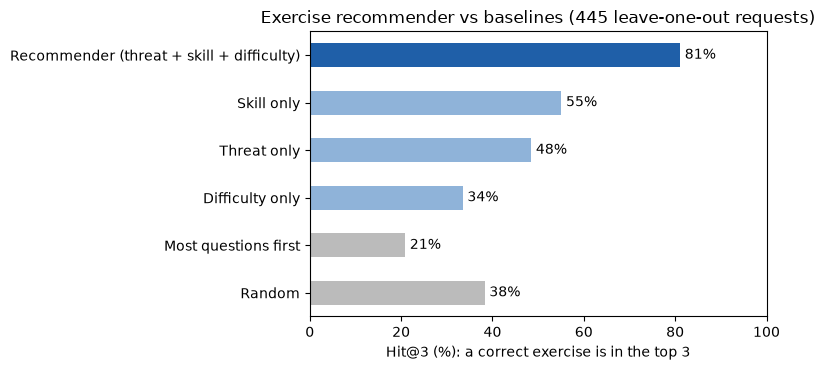

In [8]:
colors = ["#bbbbbb", "#bbbbbb", "#8fb3d9", "#8fb3d9", "#8fb3d9", "#1f5fa8"]
ax = (evaluation["hit@3"] * 100).plot(kind="barh", figsize=(8, 3.8), color=colors)
ax.set_xlabel("Hit@3 (%): a correct exercise is in the top 3")
ax.set_xlim(0, 100)
for i, v in enumerate(evaluation["hit@3"] * 100):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
ax.set_title(f"Exercise recommender vs baselines ({len(tests)} leave-one-out requests)")
plt.tight_layout()
plt.show()

#### 9. Where the recommender does well and badly
Hit@3 per manual.

*Why:* an average can hide weak spots. Manuals whose two modules have very similar profiles are harder to tell apart, which is useful to mention as a limitation.

In [9]:
tests["rank"] = full_ranks
per_manual = (tests.groupby("manual_title")["rank"]
              .agg(requests="count", hit_at_3=lambda r: (r <= 3).mean())
              .sort_values("hit_at_3"))
per_manual["hit_at_3"] = per_manual["hit_at_3"].round(2)
per_manual

,requests,hit_at_3
manual_title,,
Industrial Control Systems,59,0.64
Healthcare,61,0.74
Communications,45,0.80
Insider Threat,53,0.81
Executives,64,0.81
Ransomware,59,0.83
Vendor,49,0.92
Financial Services,55,0.96


#### 10. Saving the results
- `exercise_profiles.csv`: the readable profile of each exercise (step 3)
- `recommender_evaluation.csv`: the results table (step 7)

**Limitations to mention in the report:**
- The skill and difficulty labels come from keyword rules (`7_label_questions`); their quality is measured by the team's blind hand check there.
- Difficulty is measured from the wording of the questions (what kind of thinking they ask for). That is only a proxy for how hard an exercise is for the participants.
- The test requests are generated from the same labelled questions. This shows that the profiles separate the exercises well, but not yet that real trainers find the recommendations useful. A small independent test with trainer requests would be the next step.
- The recommender is a fixed scoring model without trained parameters.

In [10]:
profiles.reset_index(names="exercise_id").to_csv(data_dir / "exercise_profiles.csv", index=False, encoding="utf-8-sig")
evaluation.reset_index(names="model").to_csv(data_dir / "recommender_evaluation.csv", index=False, encoding="utf-8-sig")
print("Saved exercise_profiles.csv and recommender_evaluation.csv")

Saved exercise_profiles.csv and recommender_evaluation.csv


#### 11. Combined Goal 3 dataset
One row per exercise with everything the recommender uses: threats, skills, difficulty, plus the techniques, responses and outcomes from Goal 2.

*Which difficulty is used where:* the recommender scores the **question-level** labels (`Basic` / `Intermediate` / `Advanced` from `7_label_questions`). `relative_difficulty` is only a readable summary that splits the 16 exercises into the easiest, middle and hardest third.

In [11]:
# --- Combined Goal 3 dataset: one row per exercise ---
skill_share = skill_counts.div(skill_counts.sum(axis=1), axis=0)
level_share = level_counts[LEVELS].div(level_counts.sum(axis=1), axis=0)

def describe_shares(row, top=3):
    """Turn shares into readable text, e.g. 'Communication (30%); Legal & Compliance (20%)'."""
    row = row[row > 0].sort_values(ascending=False).head(top)
    return "; ".join(f"{name} ({share:.0%})" for name, share in row.items())

# exercises split into three equal groups: the easiest third, the middle third and the hardest third
relative_level = pd.qcut(level_score, 3, labels=LEVELS)

goal3_dataset = pd.DataFrame({
    "manual_title": profiles["manual_title"],
    "section": profiles["section"],
    "events": exercise_events.groupby("exercise_id").size(),
    "questions": skill_counts.sum(axis=1),
    "threats": threat_share.apply(describe_shares, axis=1, top=5),
    "skills": skill_share.apply(describe_shares, axis=1),
    "difficulty_mix": level_share.apply(describe_shares, axis=1),
    "avg_difficulty": level_score.round(2),
    "relative_difficulty": relative_level,
}).loc[ids]

goal3_dataset = (goal3_dataset
                 .join(goal2.set_index("exercise_id")[["mitre_techniques", "top_responses", "outcomes"]])
                 .reset_index(names="exercise_id"))

goal3_dataset.to_csv(data_dir / "goal3_exercise_dataset.csv", index=False, encoding="utf-8-sig")
goal3_dataset

,exercise_id,manual_title,section,events,questions,threats,skills,difficulty_mix,avg_difficulty,relative_difficulty,mitre_techniques,top_responses,outcomes
0,EX-01,Healthcare,Module 1,5,34,Phishing (33%); System Disruption (33%); Vulnerability (33%),Technical Controls (24%); Risk Management (21%); Training & Awareness (21%),Intermediate (68%); Basic (26%); Advanced (6%),1.79,Intermediate,T1566 Phishing; T1598 Phishing for Information (plausible); T1190 Exploit Public-Facing Applicat...,Filter Network Traffic; Network Segmentation; Antivirus/Antimalware; Application Isolation and S...,No Direct Impact; Security Risk; Operational Disruption
1,EX-02,Healthcare,Module 2,6,27,Data Exposure (33%); Insider Threat / Unauthorized Access (17%); Other Security Incident (17%); ...,Business Continuity & Recovery (30%); Incident Response (26%); Communication (15%),Intermediate (52%); Basic (26%); Advanced (22%),1.96,Advanced,T1078 Valid Accounts (plausible); T1621 Multi-Factor Authentication Request Generation (plausibl...,Encrypt Sensitive Information; Restrict File and Directory Permissions; User Account Management;...,Security Risk; Patient Safety; Operational Disruption; Data Exposure; Reputational Damage
2,EX-03,Vendor,Module 1,4,28,Third-Party / Supply Chain (100%),Technical Controls (32%); Third-Party Management (25%); Risk Management (21%),Intermediate (64%); Basic (32%); Advanced (4%),1.71,Basic,T1195.002 Compromise Software Supply Chain; T1199 Trusted Relationship; T1199 Trusted Relationsh...,Multi-factor Authentication; Network Segmentation; User Account Management; Update Software; Vul...,No Direct Impact; Security Risk
3,EX-04,Vendor,Module 2 – 6 months later,4,21,System Disruption (50%); Other Security Incident (25%); Third-Party / Supply Chain (25%),Incident Response (33%); Business Continuity & Recovery (29%); Third-Party Management (19%),Intermediate (81%); Basic (14%); Advanced (5%),1.90,Intermediate,T1489 Service Stop (plausible); T1499 Endpoint Denial of Service (plausible); T1195.002 Compromi...,Network Segmentation; User Account Management; Filter Network Traffic; Out-of-Band Communication...,Operational Disruption; Security Risk
4,EX-05,Ransomware,Module 1,4,27,Other Security Incident (33%); Phishing (33%); Vulnerability (33%),Risk Management (30%); Training & Awareness (26%); Business Continuity & Recovery (15%),Intermediate (52%); Basic (41%); Advanced (7%),1.67,Basic,T1190 Exploit Public-Facing Application (plausible); T1068 Exploitation for Privilege Escalation...,Antivirus/Antimalware; Application Isolation and Sandboxing; Audit; Execution Prevention; Exploi...,No Direct Impact; Security Risk
5,EX-06,Ransomware,Module 2,4,32,Data Exposure (50%); Ransomware (50%),Incident Response (31%); Business Continuity & Recovery (19%); Communication (16%),Intermediate (69%); Advanced (22%); Basic (9%),2.12,Advanced,T1048 Exfiltration Over Alternative Protocol; T1071.004 DNS (plausible); T1486 Data Encrypted fo...,User Account Management; Behavior Prevention on Endpoint; Data Backup; Data Loss Prevention; Exe...,Data Exposure; Operational Disruption; Reputational Damage
6,EX-07,Insider Threat,Module 1,5,22,Vulnerability (67%); Data Exposure (33%),Training & Awareness (27%); Risk Management (23%); Incident Response (14%),Intermediate (55%); Basic (41%); Advanced (5%),1.64,Basic,T1190 Exploit Public-Facing Application (plausible); T1068 Exploitation for Privilege Escalation...,Application Isolation and Sandboxing; Execution Prevention; Exploit Protection; Filter Network T...,Security Risk; Financial Cost; Data Exposure; Personnel Consequences
7,EX-08,Insider Threat,Module 2,7,31,Insider Threat / Unauthorized Access (71%); Third-Party / Supply Chain (14%); Vulnerability (14%),Business Continuity & Recovery (29%); Incident Response (29%); Technical Controls (19%),Intermediate (58%); Basic (29%); Advanced (13%),1.84,Intermediate,T1190 Exploit Public-Facing Application (plausible); T1068 Exploitation for Privilege Escalation...,Mul

In [ ]:
#### 12. Independent test with trainer requests
Team members wrote realistic trainer requests (threat, skill, difficulty) in `trainer_requests.csv` and, **before looking at the rankings**, listed which exercises they judge suitable. The recommender's top 3 is compared with those judgements and with the baselines.

*Why:* the leave-one-out test in step 6 only checks the model against its own labels. This test uses human judgement, so it shows whether the recommendations are actually useful.

In [ ]:
requests_path = data_dir / "trainer_requests.csv"

if not requests_path.exists():
    pd.DataFrame({"request_id": ["R01", "R02", "R03"],
                  "threat": ["Ransomware", "Phishing", ""],
                  "skill": ["Communication", "Training & Awareness", "Leadership & Decision-Making"],
                  "difficulty": ["Basic", "", "Advanced"],
                  "suitable_exercises": ["", "", ""]}).to_csv(requests_path, index=False, encoding="utf-8-sig")
    print("Created a template:", requests_path, "- fill it in, then run this cell again.")

requests = pd.read_csv(requests_path, keep_default_na=False)
requests = requests[requests["suitable_exercises"].str.strip() != ""]

if requests.empty:
    print("No judged requests yet. Fill in suitable_exercises in trainer_requests.csv first.")
else:
    for col, allowed in [("threat", THREATS), ("skill", SKILLS), ("difficulty", LEVELS)]:
        bad = set(requests[col].str.strip()) - set(allowed) - {""}
        assert not bad, f"Check the spelling in column '{col}': {bad}"

    def top3_scores(score):
        return score.sort_values(ascending=False, kind="stable").index[:3]

    rows = []
    rng = np.random.default_rng(0)
    for r in requests.itertuples():
        suitable = {e.strip() for e in r.suitable_exercises.split(";")}
        score = match_scores(r.threat.strip() or None, r.skill.strip() or None, r.difficulty.strip() or None)
        for name, top in [("Recommender", top3_scores(score)),
                          ("Most questions first", top3_scores(skill_counts.sum(axis=1).astype(float)))]:
            rows.append({"model": name, "hit@3": float(bool(suitable & set(top))), "precision@3": len(suitable & set(top)) / 3})
        random_tops = [rng.permutation(ids)[:3] for _ in range(200)]
        rows.append({"model": "Random",
                     "hit@3": np.mean([bool(suitable & set(t)) for t in random_tops]),
                     "precision@3": np.mean([len(suitable & set(t)) / 3 for t in random_tops])})

    independent = pd.DataFrame(rows).groupby("model")[["hit@3", "precision@3"]].mean().round(2)
    print(f"{len(requests)} trainer requests, judged by the team before seeing the rankings")
    display(independent.loc[["Random", "Most questions first", "Recommender"]])